In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [12]:
def build_dft_matrix(N: int) -> np.ndarray:
    """使用纯三角函数构建 N x N 离散傅里叶变换基矩阵"""
    u = np.arange(N).reshape((N, 1))  # 列向量 [0, 1, ..., N-1]^T
    x = np.arange(N).reshape((1, N))  # 行向量 [0, 1, ..., N-1]
    angle = 2.0 * np.pi * (u @ x) / N
    # 欧拉公式: exp(-i * angle) = cos(angle) - i * sin(angle)
    W = np.cos(angle) - 1j * np.sin(angle)
    return W

In [13]:
def my_fft2(img: np.ndarray) -> np.ndarray:
    """手写二维离散傅里叶变换"""
    M, N = img.shape
    W_M = build_dft_matrix(M)
    W_N = build_dft_matrix(N)
    # 两次矩阵乘法完成行列正交基投影
    return W_M @ img @ W_N

In [14]:
def my_ifft2(F: np.ndarray) -> np.ndarray:
    """手写二维离散傅里叶逆变换"""
    M, N = F.shape
    # 逆变换基矩阵为正变换基矩阵的共轭 (cos + i*sin)
    W_M_inv = np.conj(build_dft_matrix(M))
    W_N_inv = np.conj(build_dft_matrix(N))
    spatial_complex = (W_M_inv @ F @ W_N_inv) / (M * N)
    # 取实部还原图像像素值
    return np.real(spatial_complex)

In [15]:
def my_fftshift(F: np.ndarray) -> np.ndarray:
    """通过数组切片互换四个象限，将零频移至中心"""
    M, N = F.shape
    cy, cx = (M + 1) // 2, (N + 1) // 2
    top_left     = F[:cy, :cx]
    top_right    = F[:cy, cx:]
    bottom_left  = F[cy:, :cx]
    bottom_right = F[cy:, cx:]
    
    # 对角交换：右下 <-> 左上，左下 <-> 右上
    top_half = np.hstack([bottom_right, bottom_left])
    bottom_half = np.hstack([top_right, top_left])
    return np.vstack([top_half, bottom_half])

In [16]:
def my_magnitude_spectrum(F_shifted: np.ndarray) -> np.ndarray:
    """手写计算对数幅度谱：log(sqrt(Re^2 + Im^2) + 1)"""
    real_part = np.real(F_shifted)
    imag_part = np.imag(F_shifted)
    magnitude = np.sqrt(real_part**2 + imag_part**2)
    return np.log(magnitude + 1.0)

In [ ]:
def my_gaussian_kernel_2d(ksize: int, sigma: float) -> np.ndarray:
    """不依赖 cv2，从零生成二维高斯模糊核"""
    half = ksize // 2
    ax = np.arange(-half, half + 1, dtype=np.float64)
    x, y = np.meshgrid(ax, ax)
    kernel = np.exp(-(x**2 + y**2) / (2.0 * sigma**2))
    return kernel / np.sum(kernel)  # 归一化保证总和为 1，维持图像平均亮度

In [18]:
def my_frequency_filters(shape: tuple, D0: float):
    """使用向量化距离公式生成理想与高斯低通/高通遮罩"""
    M, N = shape
    cy, cx = M / 2.0, N / 2.0
    y, x = np.ogrid[:M, :N]
    # 计算每个频谱点到中心点的欧氏距离平方 D^2
    D_sq = (y - cy)**2 + (x - cx)**2
    
    ideal_lp = (D_sq <= D0**2).astype(np.float64)
    ideal_hp = 1.0 - ideal_lp
    
    gaussian_lp = np.exp(-D_sq / (2.0 * (D0**2)))
    gaussian_hp = 1.0 - gaussian_lp
    return ideal_lp, ideal_hp, gaussian_lp, gaussian_hp

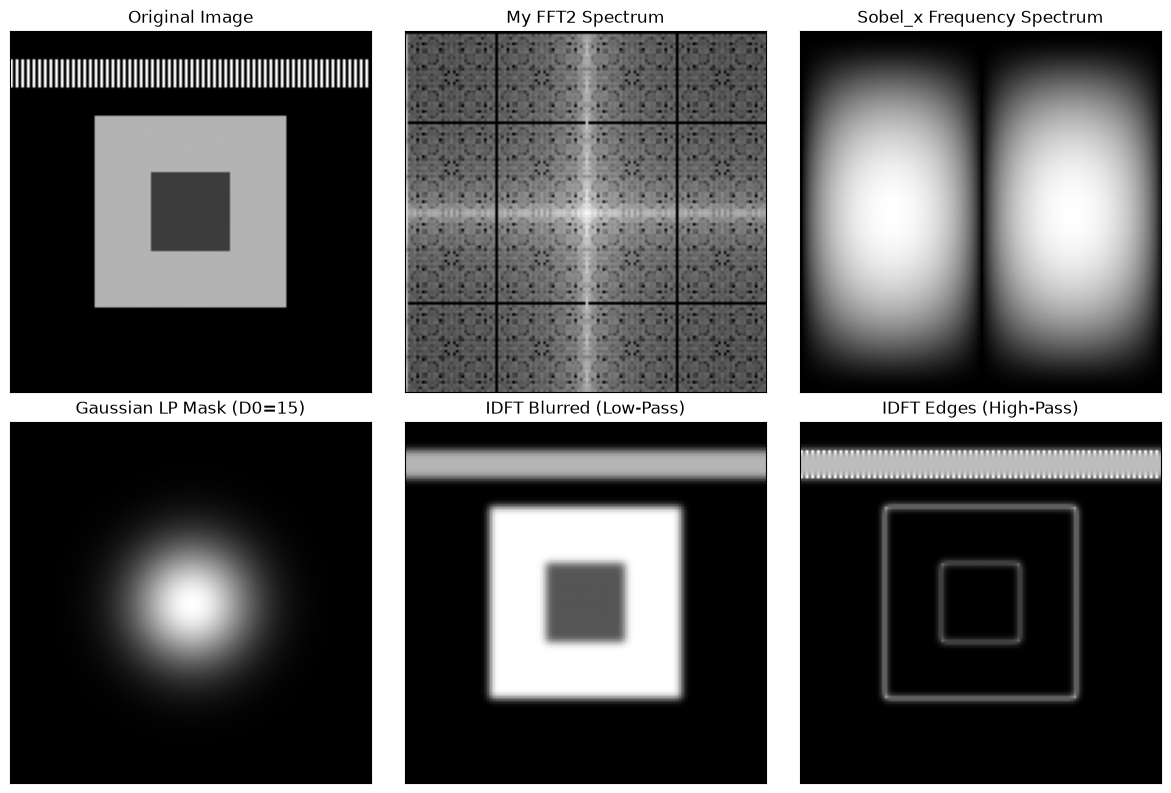

In [22]:
if __name__ == "__main__":
    # 构造一张 128x128 的合成测试图（包含大块低频背景、锐利边缘方块和高频条纹）
    N = 128
    img = np.zeros((N, N), dtype=np.float64)
    img[30:98, 30:98] = 180.0          # 亮方块（边缘为高频，内部为低频）
    img[50:78, 50:78] = 60.0           # 内部暗方块
    img[10:20, ::2] = 255.0            # 顶部高频黑白条纹
    
    # 步骤 A: 验证空间卷积核的频谱（以 Sobel_x 为例）
    sobel_pad = np.zeros((N, N))
    sobel_pad[:3, :3] = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    sobel_spec = my_magnitude_spectrum(my_fftshift(my_fft2(sobel_pad)))

    # 步骤 B: 图像转频域并中心化
    F_img = my_fft2(img)
    F_shifted = my_fftshift(F_img)
    img_spec = my_magnitude_spectrum(F_shifted)
    
    # 步骤 C: 频域逐元素相乘应用滤波（D0 = 15）
    ideal_lp, ideal_hp, gauss_lp, gauss_hp = my_frequency_filters((N, N), D0=15.0)
    
    # 低通滤波（模糊效果）与高通滤波（边缘提取效果）
    filtered_lp_shifted = F_shifted * gauss_lp
    filtered_hp_shifted = F_shifted * gauss_hp

    # 步骤 D: 逆移位并执行手写 2D IDFT 还原回空间域
    # 注：对于偶数尺寸，逆移位与正移位操作完全对称
    img_blurred = my_ifft2(my_fftshift(filtered_lp_shifted))
    img_edges   = my_ifft2(my_fftshift(filtered_hp_shifted))

    # 可视化对比
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes[0, 0].imshow(img, cmap='gray'); axes[0, 0].set_title('Original Image')
    axes[0, 1].imshow(img_spec, cmap='gray'); axes[0, 1].set_title('My FFT2 Spectrum')
    axes[0, 2].imshow(sobel_spec, cmap='gray'); axes[0, 2].set_title('Sobel_x Frequency Spectrum')
    axes[1, 0].imshow(gauss_lp, cmap='gray'); axes[1, 0].set_title('Gaussian LP Mask (D0=15)')
    axes[1, 1].imshow(img_blurred, cmap='gray'); axes[1, 1].set_title('IDFT Blurred (Low-Pass)')
    axes[1, 2].imshow(np.abs(img_edges), cmap='gray'); axes[1, 2].set_title('IDFT Edges (High-Pass)')
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.show()